# Results summary, baseline and error analysis

**Project:** Sentiment Consistency as a Signal for Detecting AI-Operated Social Media Accounts
**Student:** Sonpon Ye-shua Chief (22082706), DCIT 316

This notebook reads the saved metrics in `results/metrics/`, which are transcribed from the archived
run reports in `findings/` (the pipeline's own `results/tables/` output is overwritten on every run).
It needs **no raw data**, so anyone can run it to regenerate the figures and the
baseline/error-analysis tables used in the manuscript.

To regenerate the underlying numbers from scratch you need the Cresci-2017 data; see `README.md` and
`notebooks/run_pipeline_local.ipynb`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
MET, FIG = ROOT/'results'/'metrics', ROOT/'results'/'figures'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.edgecolor':'#52514e','axes.labelcolor':'#0b0b0b',
                     'xtick.color':'#52514e','ytick.color':'#52514e','figure.facecolor':'white'})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
comp = pd.read_csv(MET/'model_comparison_all_runs.csv')
imp = pd.read_csv(MET/'feature_importance_rf_setB.csv')
comp[['run','model','f1_metadata_only_A','f1_metadata_plus_sentiment_B','delta_f1','delta_roc_auc','mcnemar_p_value','report_py_verdict']]

,run,model,f1_metadata_only_A,f1_metadata_plus_sentiment_B,delta_f1,delta_roc_auc,mcnemar_p_value,report_py_verdict
0,1,logistic_regression,0.9067,0.9448,0.0381,0.0022,8.620000e-13,significant_improvement
1,1,random_forest,0.9801,0.9862,0.0061,0.0041,2.090000e-02,significant_but_small
2,1,svm,0.9415,0.9415,0.0000,-0.0010,1.000000e+00,no_improvement
3,2,logistic_regression,0.9062,0.9549,0.0487,NaN,2.320000e-15,significant_improvement
4,2,random_forest,0.9838,0.9866,0.0028,NaN,2.630000e-01,improvement_not_significant
5,2,svm,0.9544,0.9755,0.0211,NaN,6.350000e-06,significant_but_small
6,3,logistic_regression,0.9094,0.8630,-0.0465,0.0866,2.580000e-04,no_improvement (F1 drop; ROC-AUC improved)
7,3,random_forest,0.7781,0.9571,0.1791,0.2030,1.980000e-60,significant_improvement
8,3,svm,0.9113,0.9406,0.0293,0.1654,1.870000e-06,significant_but_small


## 1. Majority-class baseline

Feature Set A (metadata only) is the main comparison for every model, but a trivial reference point is also
needed: a classifier that labels every account *automated*. Its scores depend only on the class counts of the
stratified test split (seed 42, 20%), which we reproduce exactly from the published counts
(1,082 human / 5,471 automated).

In [2]:
y = np.array([0]*1082 + [1]*5471)
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=42)
y_tr, y_te = y[idx_tr], y[idx_te]
print('test accounts:', len(y_te), '| automated:', int(y_te.sum()), '| human:', int((y_te==0).sum()))
dummy = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(y_tr),1)), y_tr)
pred = dummy.predict(np.zeros((len(y_te),1)))
proba = dummy.predict_proba(np.zeros((len(y_te),1)))[:,1]
baseline = pd.DataFrame([{'model':'majority_class (always automated)',
    'accuracy':accuracy_score(y_te,pred),'precision':precision_score(y_te,pred),
    'recall':recall_score(y_te,pred),'f1':f1_score(y_te,pred),'roc_auc':roc_auc_score(y_te,proba),
    'human_recall':recall_score(y_te,pred,pos_label=0)}]).round(4)
baseline.to_csv(MET/'baseline_majority.csv', index=False)
baseline

test accounts: 1311 | automated: 1095 | human: 216


,model,accuracy,precision,recall,f1,roc_auc,human_recall
0,majority_class (always automated),0.8352,0.8352,1.0,0.9102,0.5,0.0


## 2. Figure 1 - F1 with and without sentiment features, all runs

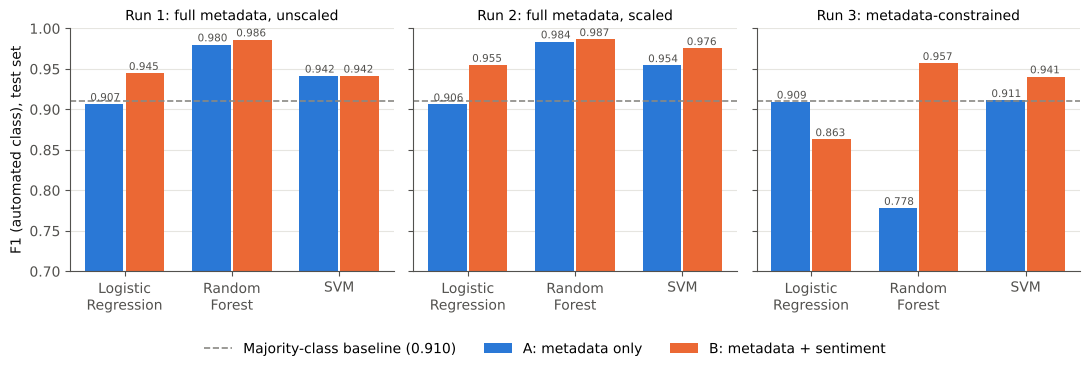

In [3]:
MAJ_F1 = baseline.loc[0,'f1']
names = {'logistic_regression':'Logistic\nRegression','random_forest':'Random\nForest','svm':'SVM'}
titles = {1:'Run 1: full metadata, unscaled',2:'Run 2: full metadata, scaled',3:'Run 3: metadata-constrained'}
fig, axes = plt.subplots(1,3, figsize=(11,3.6), sharey=True)
for ax,(run,g) in zip(axes, comp.groupby('run')):
    x = np.arange(len(g)); w = 0.36
    ax.bar(x-w/2-0.01, g.f1_metadata_only_A, w, color=BLUE, label='A: metadata only')
    ax.bar(x+w/2+0.01, g.f1_metadata_plus_sentiment_B, w, color=ORANGE, label='B: metadata + sentiment')
    ax.axhline(MAJ_F1, color=GREY, ls='--', lw=1.2, label=f'Majority-class baseline ({MAJ_F1:.3f})')
    for xi,(a,b) in enumerate(zip(g.f1_metadata_only_A, g.f1_metadata_plus_sentiment_B)):
        ax.text(xi-w/2, a+0.004, f'{a:.3f}', ha='center', fontsize=7.5, color='#52514e')
        ax.text(xi+w/2, b+0.004, f'{b:.3f}', ha='center', fontsize=7.5, color='#52514e')
    ax.set_xticks(x, [names[m] for m in g.model]); ax.set_title(titles[run], fontsize=10)
    ax.set_ylim(0.70, 1.0); ax.grid(axis='y', color='#e6e5e0', lw=0.8); ax.set_axisbelow(True)
axes[0].set_ylabel('F1 (automated class), test set')
h,l = axes[0].get_legend_handles_labels()
fig.legend(h,l, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5,-0.04))
fig.tight_layout(rect=(0,0.07,1,1)); fig.savefig(FIG/'fig1_f1_by_run.png', dpi=200, bbox_inches='tight'); plt.show()

## 3. Figure 2 - Random Forest feature importance, Run 3 (Feature Set B)

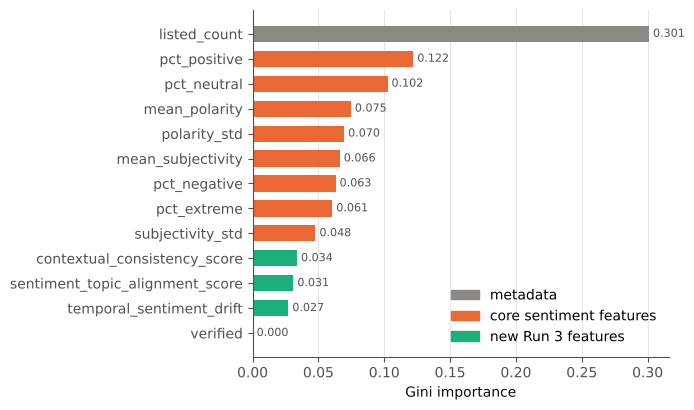

In [4]:
r3 = imp[imp.run==3].sort_values('importance')
new = {'contextual_consistency_score','temporal_sentiment_drift','sentiment_topic_alignment_score'}
meta = {'listed_count','verified'}
cols = [GREY if f in meta else (AQUA if f in new else ORANGE) for f in r3.feature]
fig, ax = plt.subplots(figsize=(7,4.2))
ax.barh(r3.feature, r3.importance, color=cols, height=0.65)
for y_,v in enumerate(r3.importance): ax.text(v+0.003, y_, f'{v:.3f}', va='center', fontsize=8, color='#52514e')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=GREY,label='metadata'),Patch(color=ORANGE,label='core sentiment features'),
                   Patch(color=AQUA,label='new Run 3 features')], frameon=False, loc='lower right')
ax.set_xlabel('Gini importance'); ax.grid(axis='x', color='#e6e5e0', lw=0.8); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG/'fig2_feature_importance_run3.png', dpi=200, bbox_inches='tight'); plt.show()

## 4. Error analysis - Run 3 confusion matrices

The archived Run 3 report gives automated-class recall and F1 for Random Forest and Logistic Regression.
With the test-set class counts fixed (1,095 automated, 216 human), recall fixes TP/FN, and F1 then fixes FP.
We search all integer confusion matrices and keep those that reproduce *both* reported values to the
reported precision. Each case has exactly one solution, so these matrices are exact, not estimates.
(SVM's recall was not archived, so it is not reconstructed.)

In [5]:
rec = pd.read_csv(MET/'run3_reported_recall.csv')
N_POS, N_NEG = int(y_te.sum()), int((y_te==0).sum())
rows = []
for _, r in rec.iterrows():
    sols = [(tp,fp) for tp in range(N_POS+1) if round(tp/N_POS,3)==r.recall_automated
            for fp in range(N_NEG+1) if round(2*tp/(2*tp+fp+(N_POS-tp)),4)==r.f1]
    assert len(sols)==1, (r.model, r.feature_set, sols)
    tp, fp = sols[0]; fn, tn = N_POS-tp, N_NEG-fp
    rows.append({'model':r.model,'feature_set':r.feature_set,'TP_automated_caught':tp,'FN_automated_missed':fn,
                 'FP_humans_flagged':fp,'TN_humans_cleared':tn,'precision':round(tp/(tp+fp),4),
                 'human_recall':round(tn/N_NEG,4),'false_flag_rate_humans':round(fp/N_NEG,4),
                 'balanced_accuracy':round((tp/N_POS+tn/N_NEG)/2,4),'macro_f1':round((2*tp/(2*tp+fp+fn)+2*tn/(2*tn+fn+fp))/2,4)})
err = pd.DataFrame(rows); err.to_csv(MET/'run3_error_analysis.csv', index=False); err

,model,feature_set,TP_automated_caught,FN_automated_missed,FP_humans_flagged,TN_humans_cleared,precision,human_recall,false_flag_rate_humans,balanced_accuracy,macro_f1
0,random_forest,A,731,364,53,163,0.9324,0.7546,0.2454,0.7111,0.6084
1,random_forest,B,1038,57,36,180,0.9665,0.8333,0.1667,0.8906,0.8759
2,logistic_regression,A,1029,66,139,77,0.8810,0.3565,0.6435,0.6481,0.6692
3,logistic_regression,B,869,226,50,166,0.9456,0.7685,0.2315,0.7811,0.7045


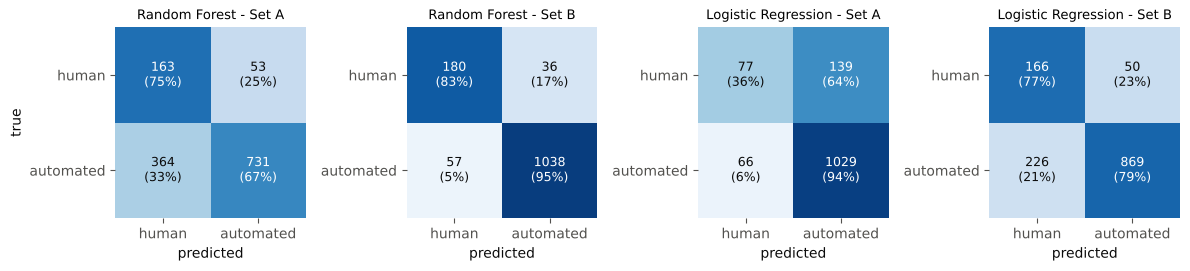

In [6]:
fig, axes = plt.subplots(1,4, figsize=(12,3.1))
lab = {'random_forest':'Random Forest','logistic_regression':'Logistic Regression'}
for ax,(_,r) in zip(axes, err.iterrows()):
    m = np.array([[r.TN_humans_cleared, r.FP_humans_flagged],[r.FN_automated_missed, r.TP_automated_caught]])
    norm = m / m.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j,i,f'{m[i,j]}\n({norm[i,j]:.0%})', ha='center', va='center', fontsize=9,
                    color='white' if norm[i,j]>0.55 else '#0b0b0b')
    ax.set_xticks([0,1],['human','automated']); ax.set_yticks([0,1],['human','automated'])
    ax.set_xlabel('predicted'); ax.set_title(f"{lab[r.model]} - Set {r.feature_set}", fontsize=9.5)
    for s in ax.spines.values(): s.set_visible(False)
axes[0].set_ylabel('true')
fig.tight_layout(); fig.savefig(FIG/'fig3_confusion_run3.png', dpi=200, bbox_inches='tight'); plt.show()

## 5. Where polarity_std (sentiment variance) ranks in each run

In [7]:
imp[imp.feature.isin(['polarity_std','pct_positive','pct_neutral','listed_count'])].pivot(index='feature', columns='run', values='rank')

run,1,2,3
feature,,,
listed_count,8,5,1
pct_neutral,7,7,3
pct_positive,5,6,2
polarity_std,9,8,5


## 6. Consistency check against the manuscript

In [8]:
assert abs(MAJ_F1 - 0.9102) < 1e-4
assert comp.query('run==3 and model=="random_forest"').delta_f1.item() == 0.1791
assert err.query('model=="random_forest" and feature_set=="A"').FN_automated_missed.item() == 364
print('All manuscript figures match the saved metrics.')

All manuscript figures match the saved metrics.
